# **DATA SCIENCE CAPSTONE PROJECT – PRCP-1027: Skin Disorder Prediction**

**PROJECT TITLE:** PRCP-1027: Skin Disorder Prediction Using Machine Learning

**TEAM CODE:** PTID-AIE-JUL-26-11142

**PROJECT CODE:** PRCP-1027

**PROJECT TYPE:** Data Science Capstone Project

**DATASET SOURCE:** DataMites Capstone Project Dataset

**DATASET NAME:** Dermatology Dataset (dataset_35_dermatology.csv)

**DATASET LINK:** https://d3ilbtxij3aepc.cloudfront.net/projects/CDS-Capstone-Projects/PRCP-1028-Skin-Disorder-Prediction-20220512T101734Z-001.zip

**DOMAIN:** Healthcare — Dermatology

**SUBMITTED BY:** Sameeksha


## **1. Problem Statement & Project Objective**

**1. Problem Statement**

The differential diagnosis of erythemato-squamous diseases is a real and challenging problem in dermatology. All six diseases in this group — Psoriasis, Seboreic dermatitis, Lichen planus, Pityriasis rosea, Chronic dermatitis and Pityriasis rubra pilaris — share the clinical features of erythema and scaling, with very little difference between them. Normally a biopsy is required for confirmation, but even histopathological features overlap heavily between these diseases, and a disease may show features of another disease at its early stage, which makes the differential diagnosis genuinely difficult in practice. The objective of this project is to analyze patient clinical and histopathological records and develop a machine learning classification model to accurately predict the skin disease category, thereby supporting faster and more reliable diagnosis.

**2. Project Objectives**

1.Perform Exploratory Data Analysis (EDA) to understand the dataset and prepare a complete data analysis report (Task 1).

2.Preprocess and prepare the clinical and histopathological data for model development.

3.Build and train multiple classification models to predict the skin disease class.

4.Evaluate and compare model performance using appropriate metrics (Task 2).

5.Select the best-performing model for production use as a clinical decision-support tool.

6.Analyze feature importance to identify the key clinical/histopathological factors influencing diagnosis.

7.Provide practical suggestions to doctors to help identify skin disease at the earliest (Task 3).

8.Summarize the challenges faced and the techniques used during the project.

**Dataset:** 366 patient records, 34 attributes (33 linear-valued clinical/histopathological features + Age) and 1 target column (class, 6 disease categories). Patient names/IDs have been removed for privacy. Family history is binary (0/1); every other clinical/histopathological attribute is graded 0–3 (0 = not present, 3 = largest amount, 1/2 = intermediate).


## **2. Import Python Libraries**

The required Python libraries are imported to perform data analysis, visualization, machine learning model development, and performance evaluation. NumPy and Pandas are used for data manipulation, Matplotlib and Seaborn are used for data visualization, and Scikit-learn provides the tools for data preprocessing, model training, and evaluating the performance of different classification algorithms.


In [1]:
# Core libraries
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
sns.set(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# Preprocessing & model selection
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler

# Models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

# Metrics
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              classification_report, confusion_matrix)

import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully.")

Libraries imported successfully.


## **3. Upload the Dataset And Domain Analysis**

**1. Upload the Dataset**

The dataset_35_dermatology.csv dataset is uploaded and loaded into the Jupyter Notebook using the Pandas library. The dataset contains clinical and histopathological attributes of dermatology patients along with the corresponding disease class, which serves as the target variable for building and evaluating machine learning classification models.

**2. Domain Analysis**

This project belongs to the healthcare / dermatology domain, where the objective is to classify patients into one of six erythemato-squamous disease categories based on clinical and histopathological observations. The dataset contains 34 attributes: 12 clinical attributes (recorded at first patient evaluation) and 22 histopathological attributes (recorded from microscopic analysis of skin biopsy samples), plus Age.

**Clinical attributes:** erythema, scaling, definite borders, itching, koebner phenomenon, polygonal papules, follicular papules, oral mucosal involvement, knee and elbow involvement, scalp involvement, family history (0/1).

**Histopathological attributes:** melanin incontinence, eosinophils in the infiltrate, PNL infiltrate, fibrosis of the papillary dermis, exocytosis, acanthosis, hyperkeratosis, parakeratosis, clubbing of the rete ridges, elongation of the rete ridges, thinning of the suprapapillary epidermis, spongiform pustule, munro microabcess, focal hypergranulosis, disappearance of the granular layer, vacuolisation and damage of basal layer, spongiosis, saw-tooth appearance of retes, follicular horn plug, perifollicular parakeratosis, inflammatory monoluclear infiltrate, band-like infiltrate. By analyzing these features, machine learning models can help dermatologists prioritise the most informative clinical/histopathological markers and make data-driven, faster diagnostic decisions.


In [2]:
# Load the dataset
df = pd.read_csv('dataset_35_dermatology.csv')
df.head()

,erythema,scaling,definite_borders,itching,koebner_phenomenon,polygonal_papules,follicular_papules,oral_mucosal_involvement,knee_and_elbow_involvement,scalp_involvement,...,disappearance_of_the_granular_layer,vacuolisation_and_damage_of_basal_layer,spongiosis,saw-tooth_appearance_of_retes,follicular_horn_plug,perifollicular_parakeratosis,inflammatory_monoluclear_inflitrate,band-like_infiltrate,Age,class
0,2,2,0,3,0,0,0,0,1,0,...,0,0,3,0,0,0,1,0,55,2
1,3,3,3,2,1,0,0,0,1,1,...,0,0,0,0,0,0,1,0,8,1
2,2,1,2,3,1,3,0,3,0,0,...,0,2,3,2,0,0,2,3,26,3
3,2,2,2,0,0,0,0,0,3,2,...,3,0,0,0,0,0,3,0,40,1
4,2,3,2,2,2,2,0,2,0,0,...,2,3,2,3,0,0,2,3,45,3


## **4. Basic Checks**

Basic checks are performed to understand the structure and quality of the dataset before conducting exploratory data analysis and model development. This includes viewing sample records, examining dataset dimensions, identifying data types, generating descriptive statistics, and obtaining summary information about the dataset.


### 4.1 Head

In [3]:
df.head()

,erythema,scaling,definite_borders,itching,koebner_phenomenon,polygonal_papules,follicular_papules,oral_mucosal_involvement,knee_and_elbow_involvement,scalp_involvement,...,disappearance_of_the_granular_layer,vacuolisation_and_damage_of_basal_layer,spongiosis,saw-tooth_appearance_of_retes,follicular_horn_plug,perifollicular_parakeratosis,inflammatory_monoluclear_inflitrate,band-like_infiltrate,Age,class
0,2,2,0,3,0,0,0,0,1,0,...,0,0,3,0,0,0,1,0,55,2
1,3,3,3,2,1,0,0,0,1,1,...,0,0,0,0,0,0,1,0,8,1
2,2,1,2,3,1,3,0,3,0,0,...,0,2,3,2,0,0,2,3,26,3
3,2,2,2,0,0,0,0,0,3,2,...,3,0,0,0,0,0,3,0,40,1
4,2,3,2,2,2,2,0,2,0,0,...,2,3,2,3,0,0,2,3,45,3


### 4.2 Tail

In [4]:
df.tail()

,erythema,scaling,definite_borders,itching,koebner_phenomenon,polygonal_papules,follicular_papules,oral_mucosal_involvement,knee_and_elbow_involvement,scalp_involvement,...,disappearance_of_the_granular_layer,vacuolisation_and_damage_of_basal_layer,spongiosis,saw-tooth_appearance_of_retes,follicular_horn_plug,perifollicular_parakeratosis,inflammatory_monoluclear_inflitrate,band-like_infiltrate,Age,class
361,2,1,1,0,1,0,0,0,0,0,...,0,0,1,0,0,0,2,0,25,4
362,3,2,1,0,1,0,0,0,0,0,...,1,0,1,0,0,0,2,0,36,4
363,3,2,2,2,3,2,0,2,0,0,...,0,3,0,3,0,0,2,3,28,3
364,2,1,3,1,2,3,0,2,0,0,...,0,2,0,1,0,0,2,3,50,3
365,3,2,2,0,0,0,0,0,3,3,...,2,0,0,0,0,0,3,0,35,1


### 4.3 Shape

In [5]:
print(f"Number of rows: {df.shape[0]}")
print(f"Number of columns: {df.shape[1]}")

Number of rows: 366
Number of columns: 35


### 4.4 Columns

In [6]:
df.columns.tolist()

['erythema',
 'scaling',
 'definite_borders',
 'itching',
 'koebner_phenomenon',
 'polygonal_papules',
 'follicular_papules',
 'oral_mucosal_involvement',
 'knee_and_elbow_involvement',
 'scalp_involvement',
 'family_history',
 'melanin_incontinence',
 'eosinophils_in_the_infiltrate',
 'PNL_infiltrate',
 'fibrosis_of_the_papillary_dermis',
 'exocytosis',
 'acanthosis',
 'hyperkeratosis',
 'parakeratosis',
 'clubbing_of_the_rete_ridges',
 'elongation_of_the_rete_ridges',
 'thinning_of_the_suprapapillary_epidermis',
 'spongiform_pustule',
 'munro_microabcess',
 'focal_hypergranulosis',
 'disappearance_of_the_granular_layer',
 'vacuolisation_and_damage_of_basal_layer',
 'spongiosis',
 'saw-tooth_appearance_of_retes',
 'follicular_horn_plug',
 'perifollicular_parakeratosis',
 'inflammatory_monoluclear_inflitrate',
 'band-like_infiltrate',
 'Age',
 'class']

### 4.5 Data Types

In [7]:
df.dtypes

,0
erythema,int64
scaling,int64
definite_borders,int64
itching,int64
koebner_phenomenon,int64
polygonal_papules,int64
follicular_papules,int64
oral_mucosal_involvement,int64
knee_and_elbow_involvement,int64
scalp_involvement,int64


### 4.6 Info

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 366 entries, 0 to 365
Data columns (total 35 columns):
 #   Column                                    Non-Null Count  Dtype 
---  ------                                    --------------  ----- 
 0   erythema                                  366 non-null    int64 
 1   scaling                                   366 non-null    int64 
 2   definite_borders                          366 non-null    int64 
 3   itching                                   366 non-null    int64 
 4   koebner_phenomenon                        366 non-null    int64 
 5   polygonal_papules                         366 non-null    int64 
 6   follicular_papules                        366 non-null    int64 
 7   oral_mucosal_involvement                  366 non-null    int64 
 8   knee_and_elbow_involvement                366 non-null    int64 
 9   scalp_involvement                         366 non-null    int64 
 10  family_history                            366 non-

### 4.7 Describe

In [9]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
erythema,366.0,NaN,NaN,NaN,2.068306,0.664753,0.0,2.0,2.0,2.0,3.0
scaling,366.0,NaN,NaN,NaN,1.795082,0.701527,0.0,1.0,2.0,2.0,3.0
definite_borders,366.0,NaN,NaN,NaN,1.54918,0.907525,0.0,1.0,2.0,2.0,3.0
itching,366.0,NaN,NaN,NaN,1.36612,1.138299,0.0,0.0,1.0,2.0,3.0
koebner_phenomenon,366.0,NaN,NaN,NaN,0.63388,0.908016,0.0,0.0,0.0,1.0,3.0
polygonal_papules,366.0,NaN,NaN,NaN,0.448087,0.957327,0.0,0.0,0.0,0.0,3.0
follicular_papules,366.0,NaN,NaN,NaN,0.166667,0.570588,0.0,0.0,0.0,0.0,3.0
oral_mucosal_involvement,366.0,NaN,NaN,NaN,0.377049,0.834147,0.0,0.0,0.0,0.0,3.0
knee_and_elbow_involvement,366.0,NaN,NaN,NaN,0.614754,0.982979,0.0,0.0,0.0,1.0,3.0
scalp_involvement,366.0,NaN,NaN,NaN,0.519126,0.905639,0.0,0.0,0.0,1.0,3.0


## **5. Data Quality Checks**

Data quality checks are performed to identify issues such as missing values, placeholder characters, and duplicate records that could affect the reliability of the analysis and the performance of the machine learning models. This step ensures that the dataset is clean, consistent, and ready for exploratory data analysis and preprocessing.


### 5.1 Missing Values

In [10]:
print("Missing values per column:")
df.isnull().sum()[df.isnull().sum() > 0]

Missing values per column:


,0


### 5.2 '?' Values

The Age column is stored as an object/string dtype instead of numeric — this is a strong signal that it contains a placeholder character (commonly `'?'`) for missing values instead of NaN.

In [11]:
# Check for '?' placeholders across all columns
for col in df.columns:
    q_count = (df[col] == '?').sum()
    if q_count > 0:
        print(f"Column '{col}': {q_count} '?' values")

Column 'Age': 8 '?' values


### 5.3 Duplicate Records

In [12]:
duplicate_count = df.duplicated().sum()
print(f"Number of duplicate rows: {duplicate_count}")

Number of duplicate rows: 0


## **6. Exploratory Data Analysis (EDA) — Data Analysis Report (Task 1)**

Exploratory Data Analysis (EDA) is performed to gain a comprehensive understanding of the dataset before building machine learning models. This process helps identify the distribution of the target variable (disease class), understand the characteristics of each clinical and histopathological feature, analyze the Age distribution across classes, detect outliers, and analyze relationships/correlations among variables. EDA also reveals patterns and trends within the data, enabling informed decisions regarding data preprocessing, feature selection, and model development. A thorough EDA ensures that the dataset is reliable, well-understood, and suitable for building accurate and robust classification models — fulfilling the Task 1 requirement of the problem statement.


### 6.1 Target Distribution

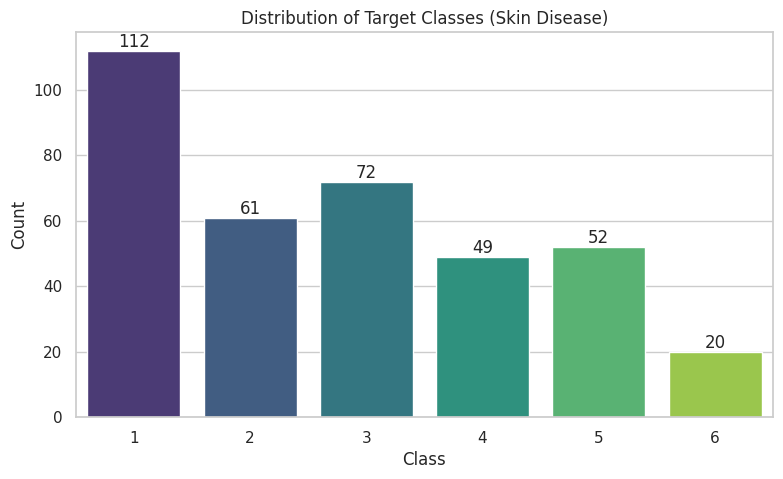

class
Psoriasis                   112
Lichen planus                72
Seboreic dermatitis          61
Chronic dermatitis           52
Pityriasis rosea             49
Pityriasis rubra pilaris     20
Name: count, dtype: int64


In [13]:
class_names = {
    1: 'Psoriasis', 2: 'Seboreic dermatitis', 3: 'Lichen planus',
    4: 'Pityriasis rosea', 5: 'Chronic dermatitis', 6: 'Pityriasis rubra pilaris'
}

plt.figure(figsize=(9, 5))
ax = sns.countplot(x='class', data=df, palette='viridis')
plt.title('Distribution of Target Classes (Skin Disease)')
plt.xlabel('Class')
plt.ylabel('Count')
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width()/2, p.get_height()),
                ha='center', va='bottom')
plt.show()

print(df['class'].value_counts().rename(index=class_names))

### 6.2 Feature Distributions

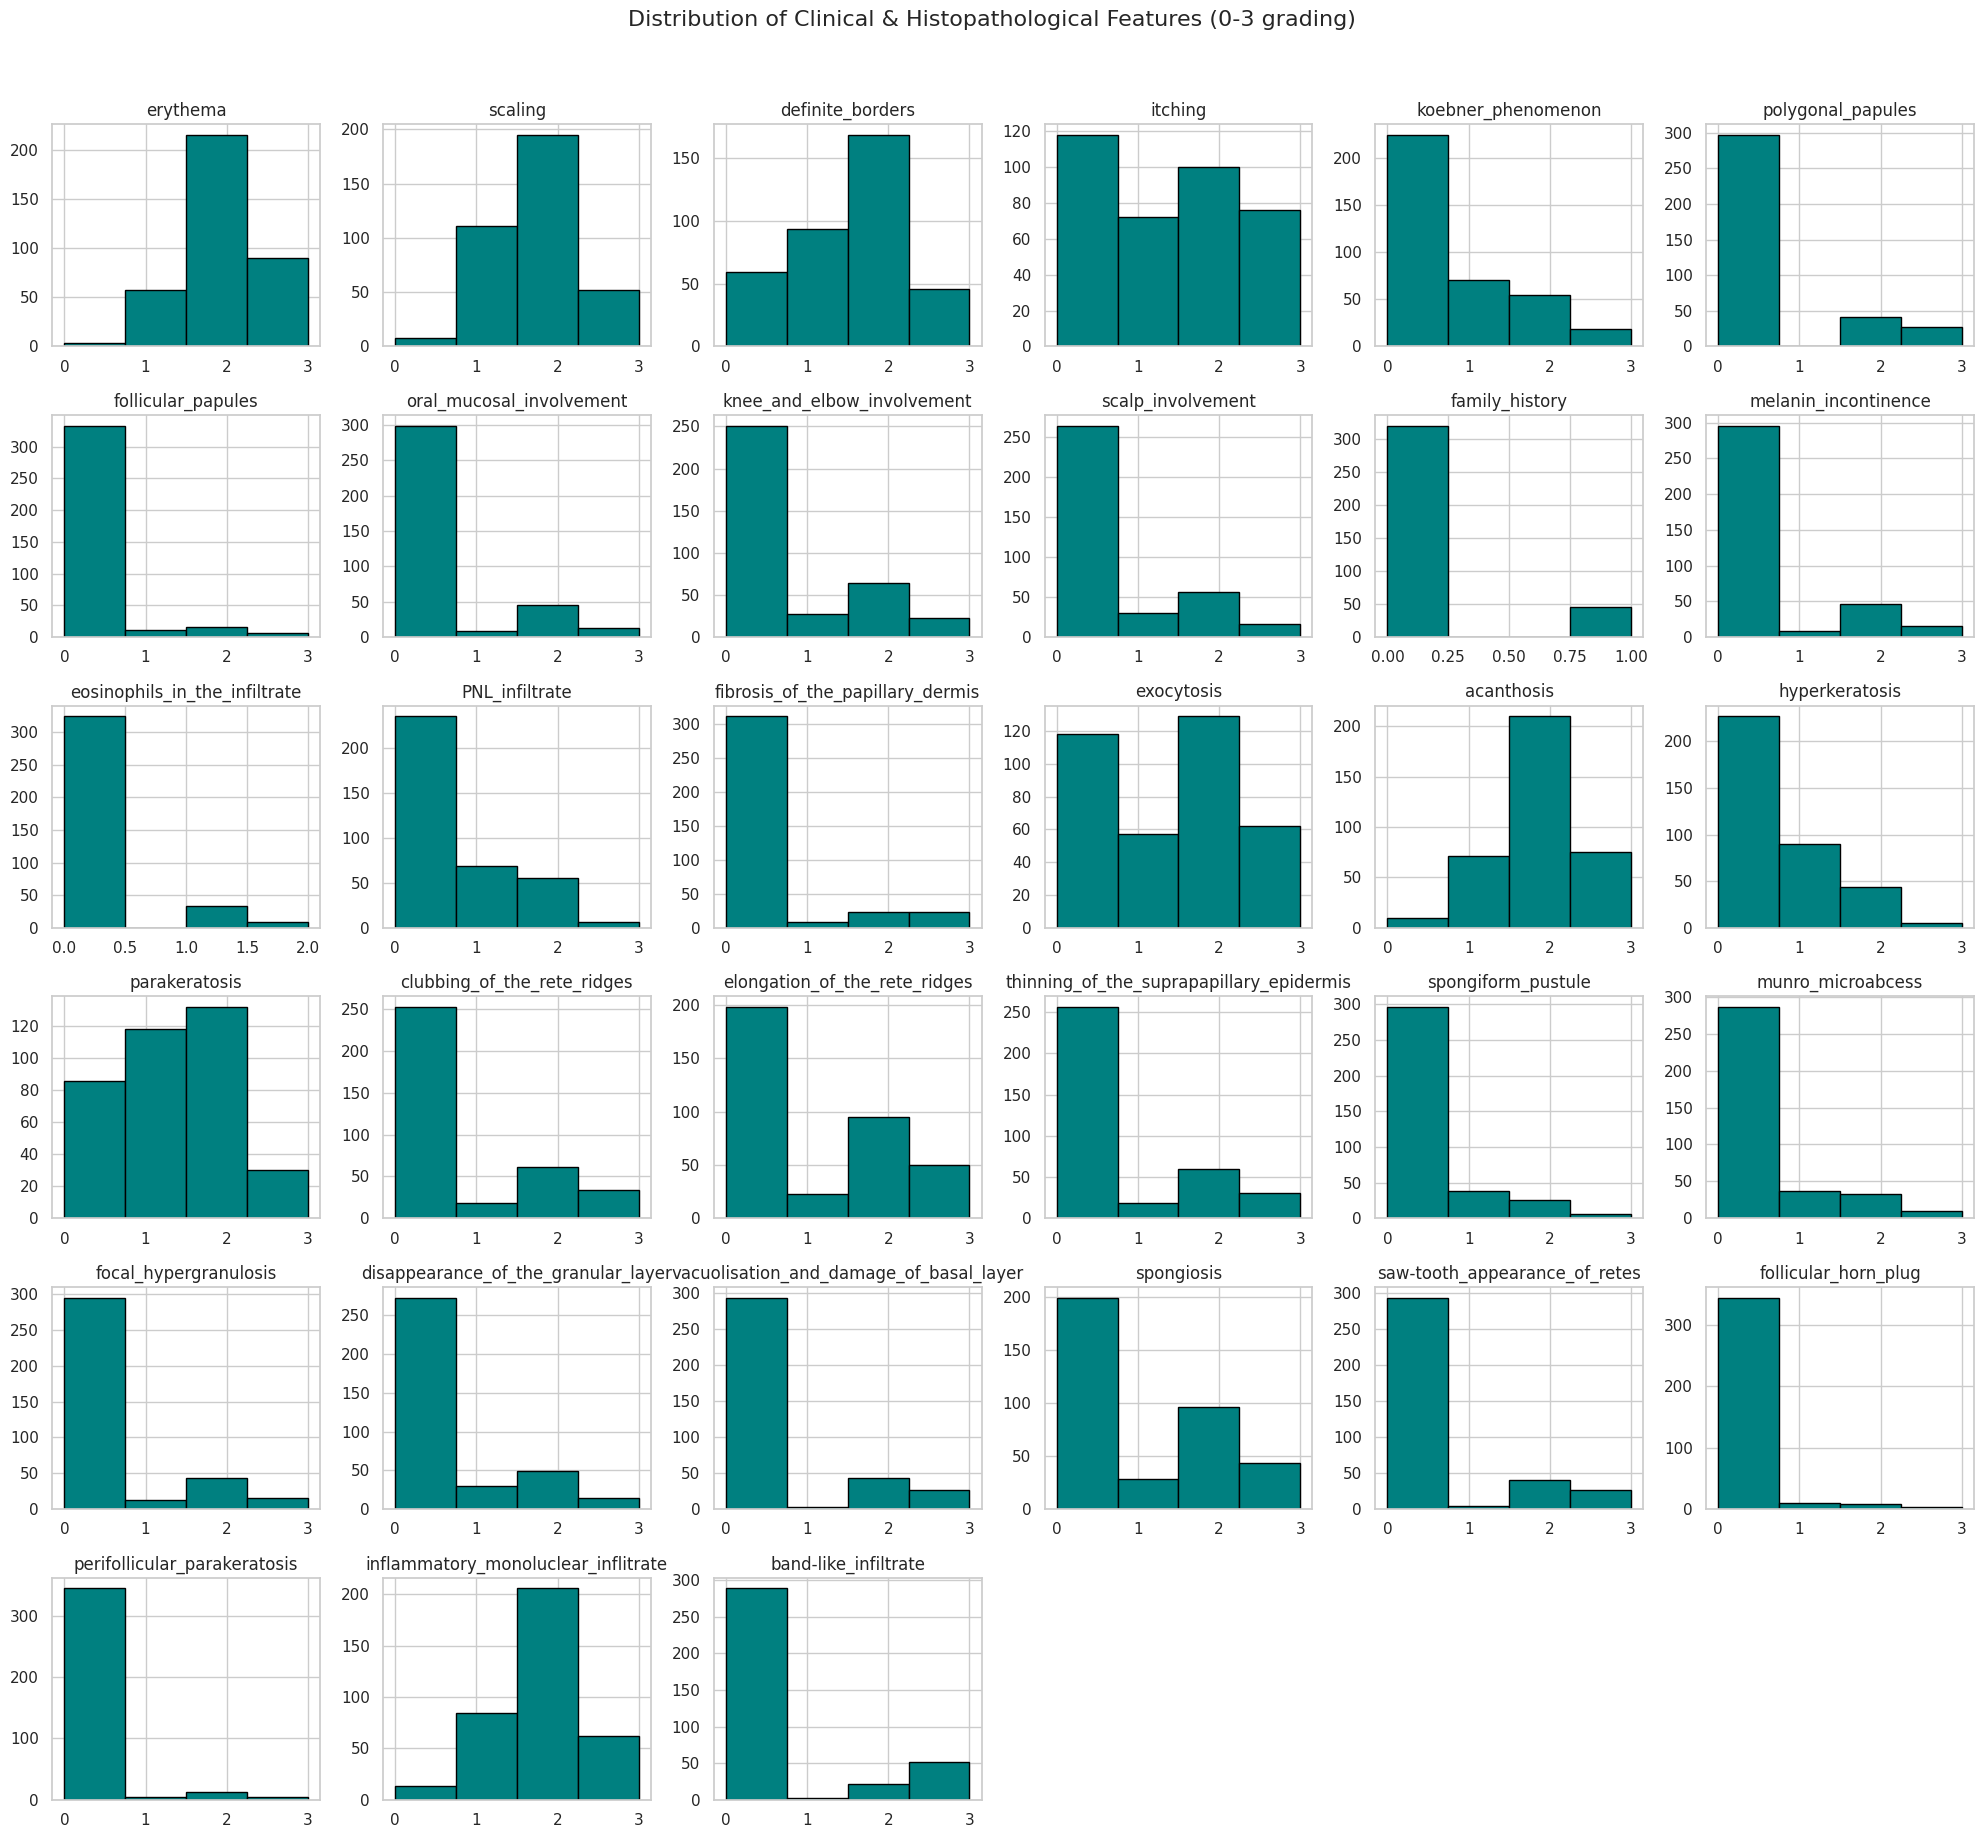

In [14]:
# Histograms of all clinical/histopathological (0-3 graded) features
feature_cols = [c for c in df.columns if c not in ['Age', 'class']]

df[feature_cols].hist(figsize=(20, 18), bins=4, color='teal', edgecolor='black')
plt.suptitle('Distribution of Clinical & Histopathological Features (0-3 grading)', y=1.02, fontsize=16)
plt.tight_layout()
plt.show()

### 6.3 Age Analysis

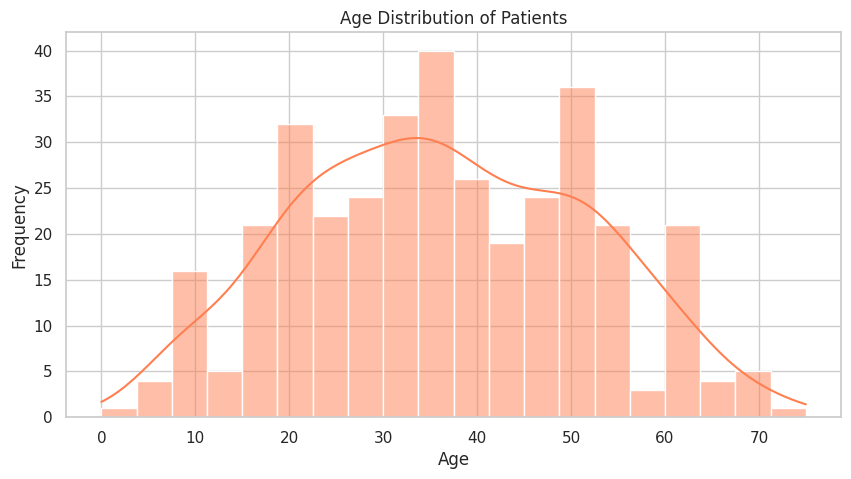

count    358.000000
mean      36.296089
std       15.324557
min        0.000000
25%       25.000000
50%       35.000000
75%       49.750000
max       75.000000
Name: Age, dtype: float64


In [15]:
age_numeric = pd.to_numeric(df['Age'], errors='coerce')

plt.figure(figsize=(10, 5))
sns.histplot(age_numeric.dropna(), bins=20, kde=True, color='coral')
plt.title('Age Distribution of Patients')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.show()

print(age_numeric.describe())

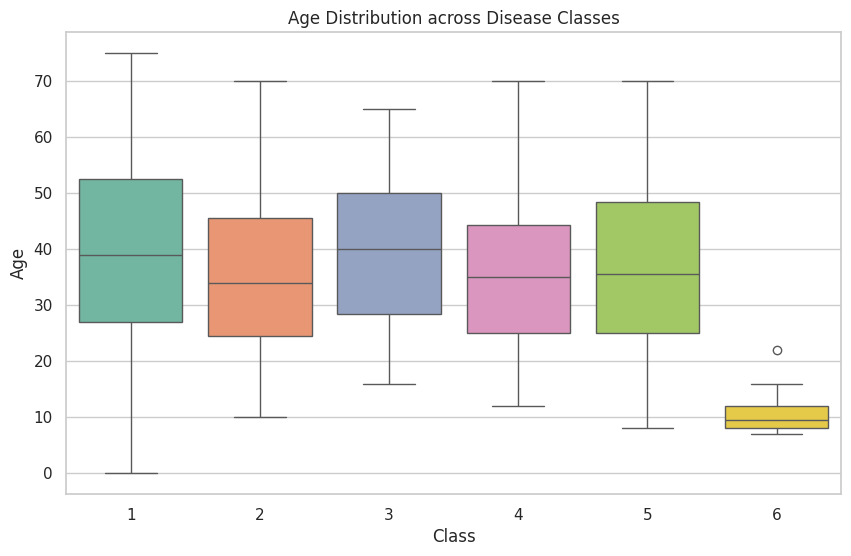

In [16]:
plt.figure(figsize=(10, 6))
sns.boxplot(x='class', y=age_numeric, data=df, palette='Set2')
plt.title('Age Distribution across Disease Classes')
plt.xlabel('Class')
plt.ylabel('Age')
plt.show()

### 6.4 Outlier Analysis

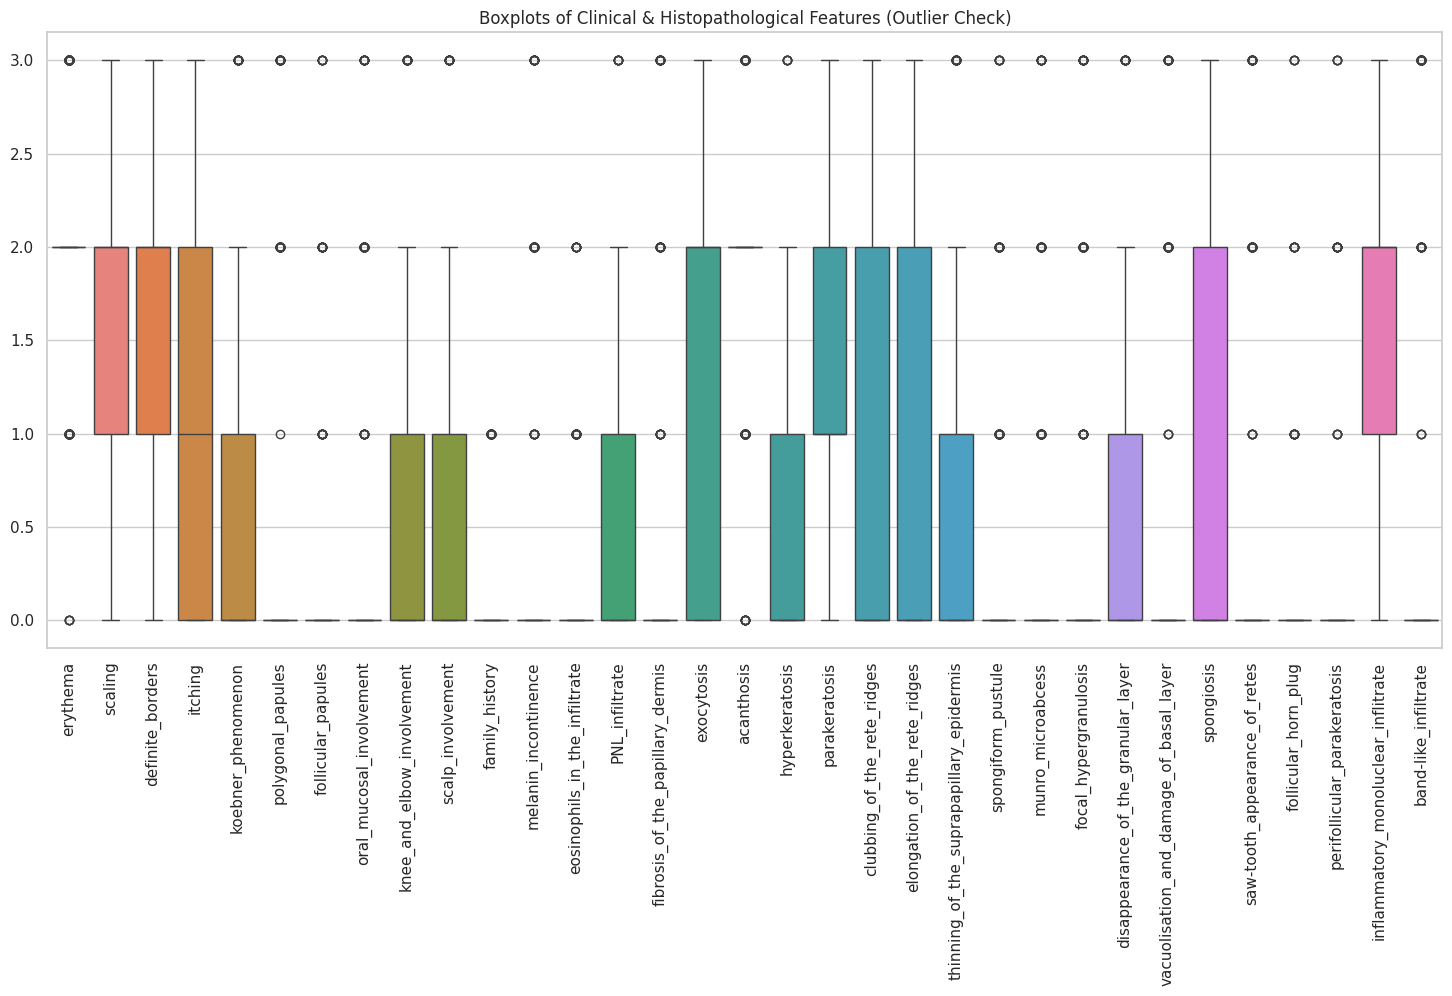

In [17]:
plt.figure(figsize=(18, 8))
sns.boxplot(data=df[feature_cols])
plt.xticks(rotation=90)
plt.title('Boxplots of Clinical & Histopathological Features (Outlier Check)')
plt.show()

# Since these are ordinal (0-3) grading scores, extreme statistical outliers are not
# expected in the usual continuous-variable sense; boxplots mainly highlight low-frequency grades.

### 6.5 Correlation Analysis

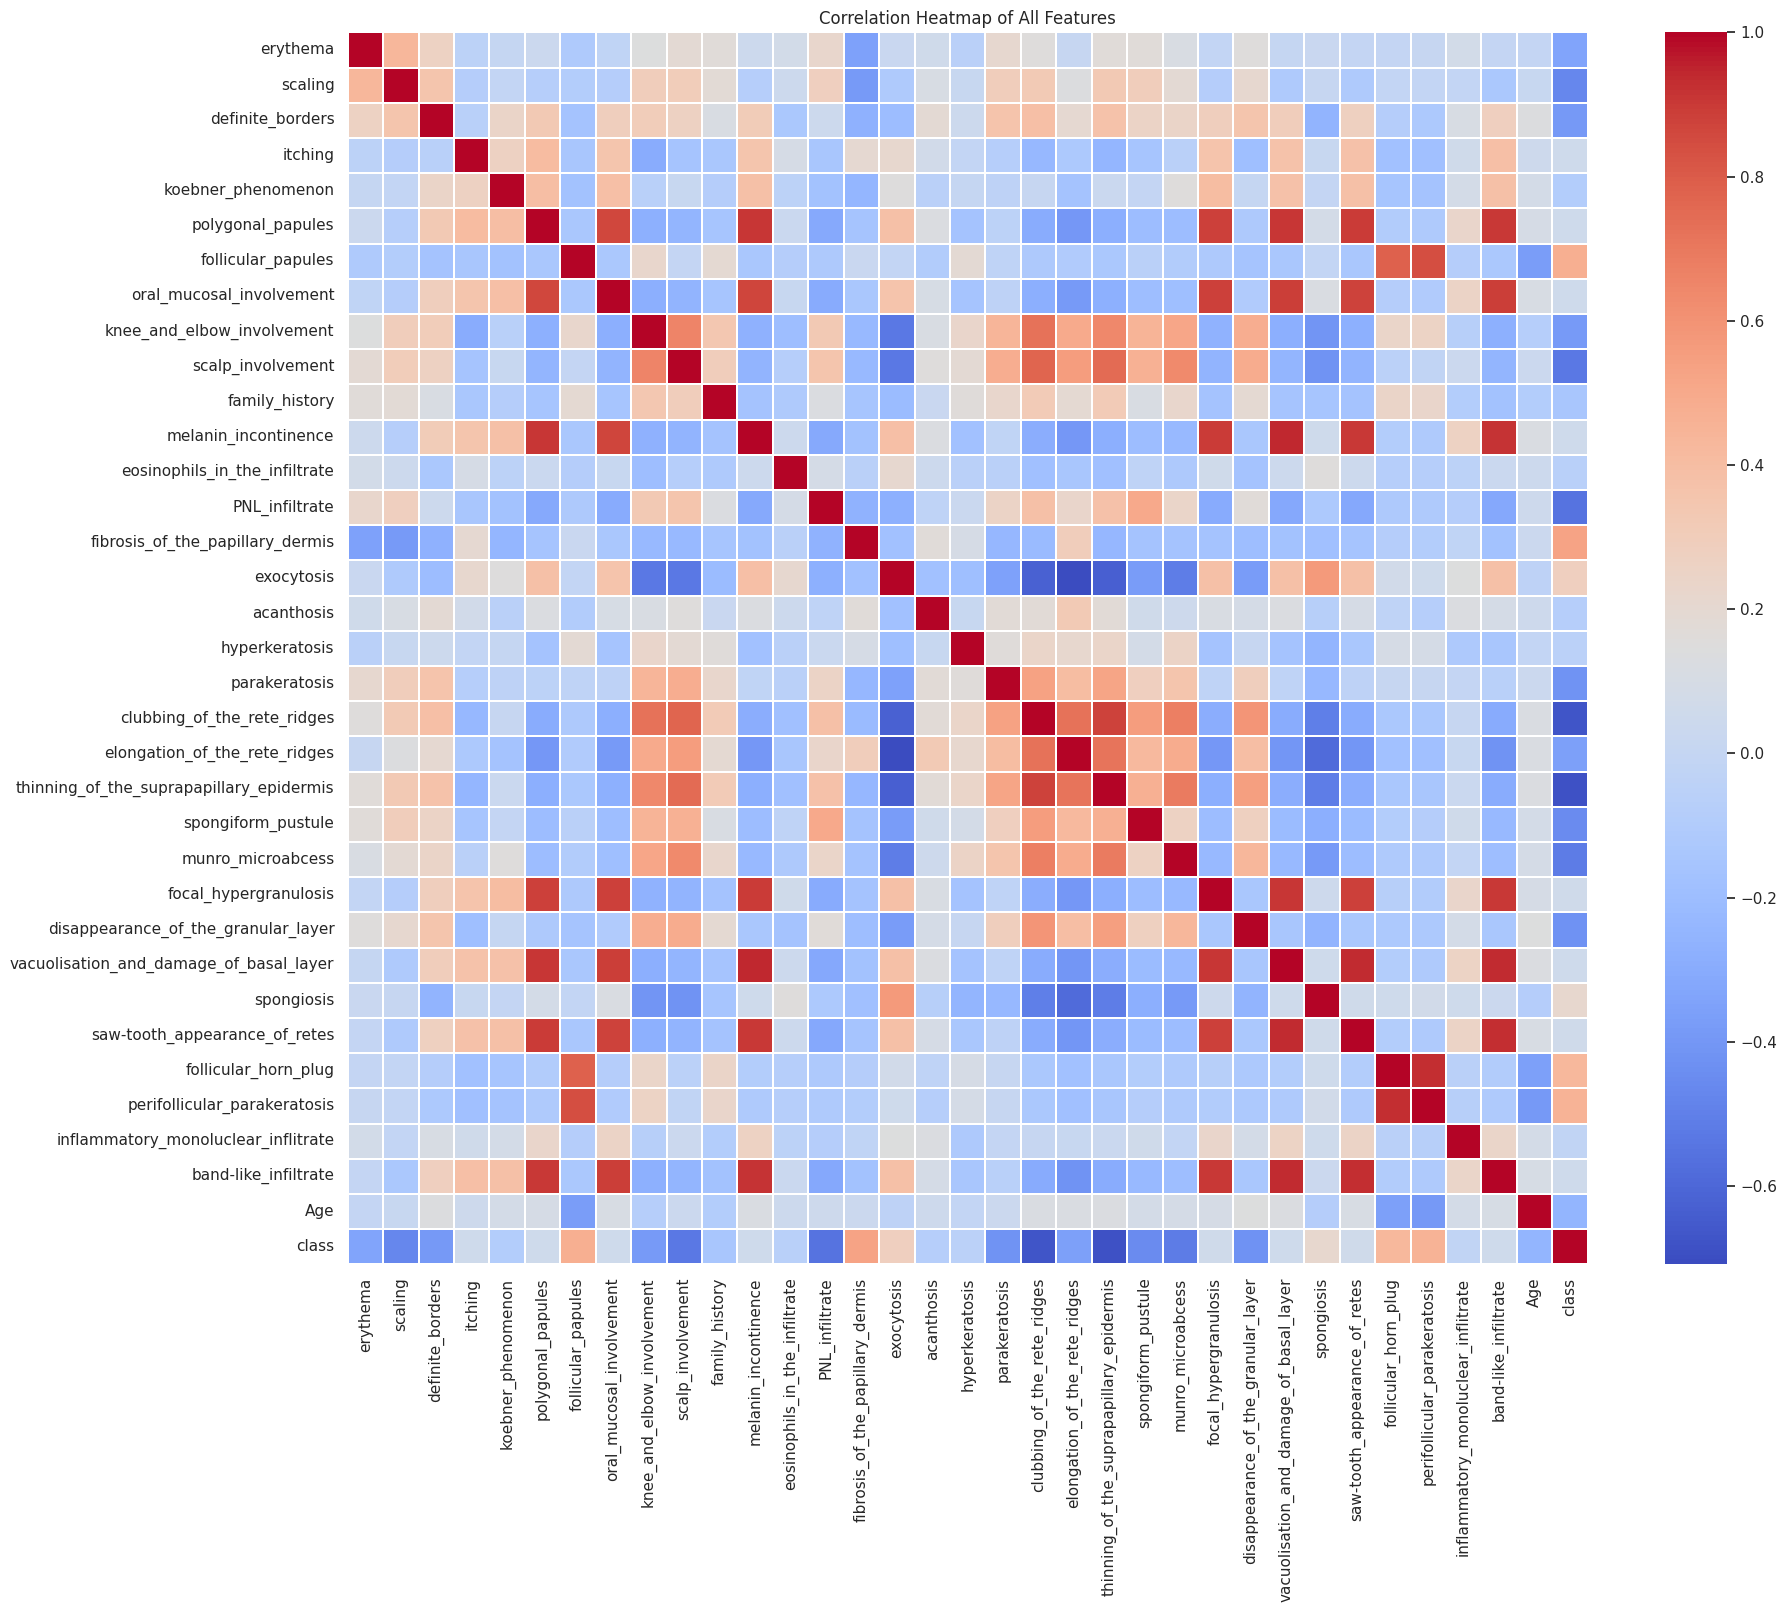

In [18]:
corr_df = df.copy()
corr_df['Age'] = pd.to_numeric(corr_df['Age'], errors='coerce')

plt.figure(figsize=(20, 16))
sns.heatmap(corr_df.corr(), cmap='coolwarm', annot=False, linewidths=0.3)
plt.title('Correlation Heatmap of All Features')
plt.show()

Top 10 features correlated with target class:
thinning_of_the_suprapapillary_epidermis   -0.684864
clubbing_of_the_rete_ridges                -0.668781
PNL_infiltrate                             -0.550195
scalp_involvement                          -0.533208
fibrosis_of_the_papillary_dermis            0.526976
munro_microabcess                          -0.520995
follicular_papules                          0.477813
scaling                                    -0.468688
perifollicular_parakeratosis                0.457025
spongiform_pustule                         -0.449407
Name: class, dtype: float64


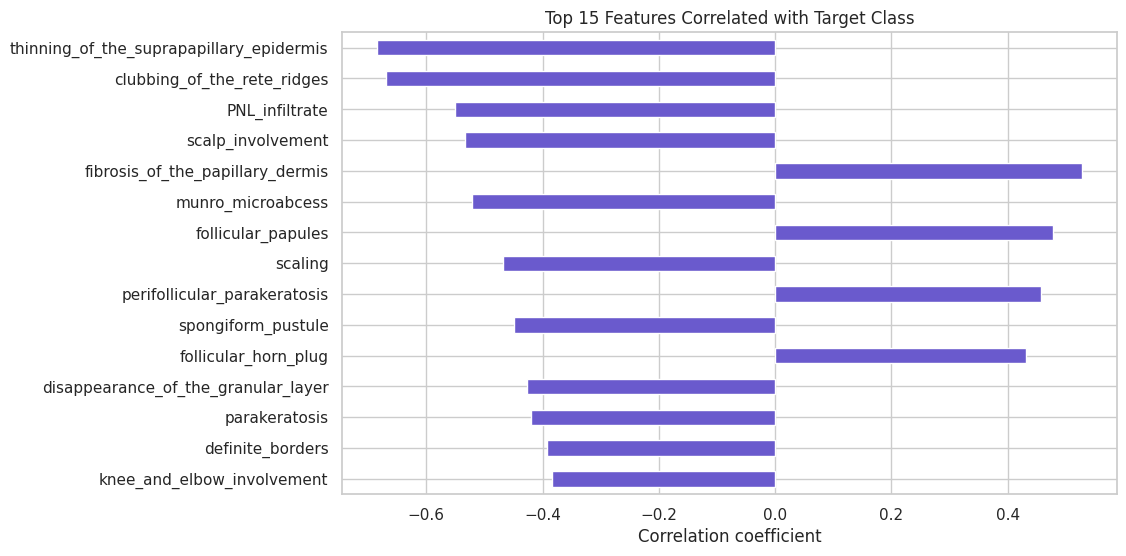

In [19]:
# Top features most correlated with the target class
target_corr = corr_df.corr()['class'].drop('class').sort_values(key=abs, ascending=False)
print("Top 10 features correlated with target class:")
print(target_corr.head(10))

plt.figure(figsize=(10, 6))
target_corr.head(15).plot(kind='barh', color='slateblue')
plt.title('Top 15 Features Correlated with Target Class')
plt.xlabel('Correlation coefficient')
plt.gca().invert_yaxis()
plt.show()

###**EDA Summary (Task 1 Conclusion):**
1.The dataset contains 366 patient records with 34 input features and 1 target variable (class), providing sufficient information for skin disease classification.

2.The dataset has no NaN missing values, but the Age column contains 8 `'?'` placeholder values that need to be treated before modelling; no duplicate rows were found.

3.The target class is imbalanced: class 1 (Psoriasis) is the most frequent, while class 6 (Pityriasis rubra pilaris) is the least frequent, which needs to be handled carefully during evaluation.


4.Most clinical/histopathological features are ordinal (0–3) and right- or left-skewed depending on the disease category, which is expected since each feature is diagnostic of specific diseases.

5.Age roughly follows a broad distribution from childhood to the elderly, with the median around the 30s–40s; some classes (e.g., pityriasis rosea) skew younger while others (e.g., chronic dermatitis) skew older.

6.Several histopathological features (e.g., fibrosis of the papillary dermis, clubbing of the rete ridges, saw-tooth appearance of retes, follicular horn plug) show strong correlation with specific disease classes, confirming their diagnostic value as documented in dermatology literature. Overall, the feature set appears highly informative for the classification task.


## **7. Data Preprocessing (Train/Test Split) — Task 2**

Data preprocessing is performed to prepare the dataset for model development, as required by Task 2 of the problem statement. This includes treating the `'?'` placeholder values in `Age`, converting `Age` to a proper numeric type, separating the features (X) from the target (y), splitting the data into training and test sets using a stratified split (to preserve the class proportions given the imbalance), and scaling the features using StandardScaler so that distance/kernel-based algorithms (Logistic Regression, KNN, SVM) are not biased by feature magnitude.


### 7.1 Missing Value Treatment

In [20]:
df_clean = df.copy()

# Replace '?' with NaN, then convert Age to numeric
df_clean['Age'] = df_clean['Age'].replace('?', np.nan)
df_clean['Age'] = pd.to_numeric(df_clean['Age'])

print(f"Missing Age values before imputation: {df_clean['Age'].isnull().sum()}")

# Impute missing Age with the median (robust to outliers, preserves ordinal-like nature)
age_median = df_clean['Age'].median()
df_clean['Age'] = df_clean['Age'].fillna(age_median)

print(f"Missing Age values after imputation: {df_clean['Age'].isnull().sum()}")
print(f"Median age used for imputation: {age_median}")

Missing Age values before imputation: 8
Missing Age values after imputation: 0
Median age used for imputation: 35.0


### 7.2 Age Conversion

In [21]:
# Age is now a clean numeric (int) column
df_clean['Age'] = df_clean['Age'].astype(int)
df_clean['Age'].describe()

,Age
count,366.000000
mean,36.267760
std,15.156875
min,0.000000
25%,25.000000
50%,35.000000
75%,48.000000
max,75.000000


### 7.3 X / y Separation

In [22]:
X = df_clean.drop(columns=['class'])
y = df_clean['class']

print(f"X shape: {X.shape}")
print(f"y shape: {y.shape}")

X shape: (366, 34)
y shape: (366,)


### 7.4 Train-Test Split

In [23]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training set size: {X_train.shape}")
print(f"Testing set size:  {X_test.shape}")

Training set size: (292, 34)
Testing set size:  (74, 34)


### 7.5 Feature Scaling

In [24]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

X_train_scaled = pd.DataFrame(X_train_scaled, columns=X.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X.columns, index=X_test.index)

X_train_scaled.head()

,erythema,scaling,definite_borders,itching,koebner_phenomenon,polygonal_papules,follicular_papules,oral_mucosal_involvement,knee_and_elbow_involvement,scalp_involvement,...,focal_hypergranulosis,disappearance_of_the_granular_layer,vacuolisation_and_damage_of_basal_layer,spongiosis,saw-tooth_appearance_of_retes,follicular_horn_plug,perifollicular_parakeratosis,inflammatory_monoluclear_inflitrate,band-like_infiltrate,Age
215,-0.074662,1.682317,0.472404,1.430488,2.640559,1.648973,-0.291486,1.924817,-0.628391,-0.574871,...,3.035442,1.798415,1.662623,0.021215,1.624721,-0.237745,-0.233713,0.205006,1.315245,-0.622773
299,-0.074662,0.282783,-0.622374,1.430488,-0.692481,-0.462870,-0.291486,-0.451701,-0.628391,-0.574871,...,-0.467914,-0.525201,-0.480803,-0.863767,-0.469842,-0.237745,-0.233713,0.205006,-0.500601,0.987087
148,-0.074662,0.282783,0.472404,-1.230037,1.529546,-0.462870,-0.291486,-0.451701,-0.628391,-0.574871,...,-0.467914,-0.525201,-0.480803,0.906198,-0.469842,-0.237745,-0.233713,-1.187128,-0.500601,-0.429590
270,-0.074662,0.282783,-0.622374,-1.230037,0.418532,-0.462870,-0.291486,-0.451701,-0.628391,-0.574871,...,-0.467914,0.636607,-0.480803,1.791181,-0.469842,-0.237745,-0.233713,0.205006,-0.500601,1.631031
331,-1.528082,-1.116752,-0.622374,-1.230037,0.418532,-0.462870,-0.291486,-0.451701,-0.628391,-0.574871,...,-0.467914,-0.525201,-0.480803,0.906198,-0.469842,-0.237745,-0.233713,1.597141,-0.500601,-0.944746


## **8. Model Selection & Building**

To predict the skin disease class, multiple machine learning classification algorithms are trained and evaluated. Instead of relying on a single model, six different classifiers are developed and compared to identify the most accurate and reliable model for this classification task. This approach satisfies the Model Comparison Report requirement and helps select the most suitable model for production/clinical use.

**1.Model 1 — Logistic Regression** — a simple, interpretable baseline classification model that predicts the probability of each disease class.

**2.Model 2 — Decision Tree Classifier** — a tree-based model that learns decision rules from the clinical and histopathological features.

**3.Model 3 — Random Forest Classifier** — an ensemble model that combines multiple decision trees to improve accuracy and reduce overfitting.

**4.Model 4 — K-Nearest Neighbors (KNN)** — a distance-based algorithm that classifies a patient based on the most similar patients in the training data.

**5.Model 5 — Support Vector Machine (SVM)** — a powerful classifier that finds the optimal boundary between the different disease classes.

**6.Model 6 — Gradient Boosting Classifier** — an ensemble boosting algorithm that builds decision trees sequentially to achieve high predictive performance.


In [25]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42),
    'KNN': KNeighborsClassifier(),
    'SVM': SVC(probability=True, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42)
}

trained_models = {}

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    trained_models[name] = model
    print(f"{name} trained.")

Logistic Regression trained.
Decision Tree trained.
Random Forest trained.
KNN trained.
SVM trained.
Gradient Boosting trained.


### 8.1 Logistic Regression

In [26]:
lr_model = trained_models['Logistic Regression']
y_pred_lr = lr_model.predict(X_test_scaled)
print("Logistic Regression trained and predictions generated.")

Logistic Regression trained and predictions generated.


### 8.2 Decision Tree

In [27]:
dt_model = trained_models['Decision Tree']
y_pred_dt = dt_model.predict(X_test_scaled)
print("Decision Tree trained and predictions generated.")

Decision Tree trained and predictions generated.


### 8.3 Random Forest

In [28]:
rf_model = trained_models['Random Forest']
y_pred_rf = rf_model.predict(X_test_scaled)
print("Random Forest trained and predictions generated.")

Random Forest trained and predictions generated.


### 8.4 KNN

In [29]:
knn_model = trained_models['KNN']
y_pred_knn = knn_model.predict(X_test_scaled)
print("KNN trained and predictions generated.")

KNN trained and predictions generated.


### 8.5 SVM

In [30]:
svm_model = trained_models['SVM']
y_pred_svm = svm_model.predict(X_test_scaled)
print("SVM trained and predictions generated.")

SVM trained and predictions generated.


### 8.6 Gradient Boosting

In [31]:
gb_model = trained_models['Gradient Boosting']
y_pred_gb = gb_model.predict(X_test_scaled)
print("Gradient Boosting trained and predictions generated.")

Gradient Boosting trained and predictions generated.


## **9. Model Evaluation**

The six trained models are evaluated on the held-out test set using multiple performance metrics — Accuracy, Precision, Recall, F1-Score, Classification Report and Confusion Matrix. Using several metrics together (rather than accuracy alone) is important here because the disease classes are imbalanced, so a model could look good on accuracy while performing poorly on the minority classes.


In [32]:
predictions = {
    'Logistic Regression': y_pred_lr,
    'Decision Tree': y_pred_dt,
    'Random Forest': y_pred_rf,
    'KNN': y_pred_knn,
    'SVM': y_pred_svm,
    'Gradient Boosting': y_pred_gb
}

results = []
for name, y_pred in predictions.items():
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, average='weighted', zero_division=0),
        'Recall': recall_score(y_test, y_pred, average='weighted', zero_division=0),
        'F1 Score': f1_score(y_test, y_pred, average='weighted', zero_division=0)
    })

results_df = pd.DataFrame(results).sort_values('F1 Score', ascending=False).reset_index(drop=True)
results_df

,Model,Accuracy,Precision,Recall,F1 Score
0,SVM,0.972973,0.977477,0.972973,0.972973
1,Logistic Regression,0.959459,0.968815,0.959459,0.960642
2,Random Forest,0.959459,0.960688,0.959459,0.959543
3,Decision Tree,0.959459,0.964619,0.959459,0.959392
4,Gradient Boosting,0.932432,0.933277,0.932432,0.930944
5,KNN,0.905405,0.919305,0.905405,0.908094


### 9.1 Accuracy

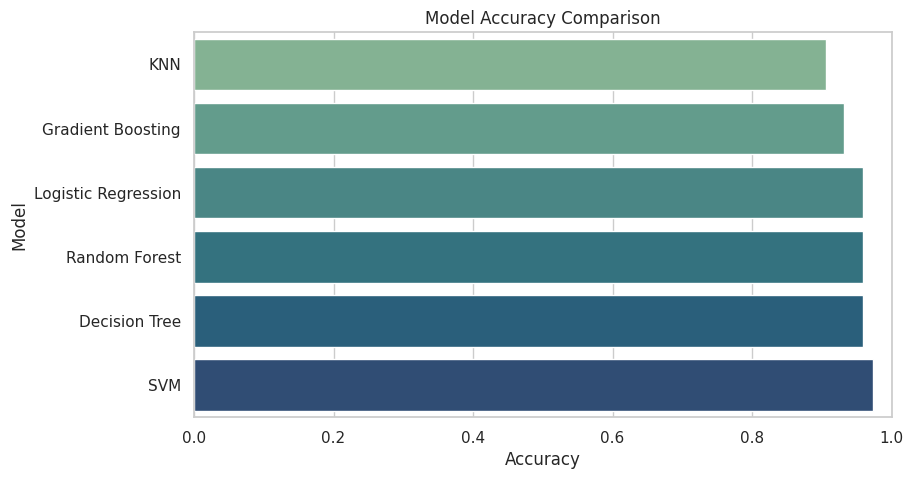

In [33]:
plt.figure(figsize=(9, 5))
sns.barplot(x='Accuracy', y='Model', data=results_df.sort_values('Accuracy'), palette='crest')
plt.title('Model Accuracy Comparison')
plt.xlim(0, 1)
plt.show()

### 9.2 Precision

In [34]:
for name, y_pred in predictions.items():
    p = precision_score(y_test, y_pred, average='weighted', zero_division=0)
    print(f"{name:22s}: Precision = {p:.4f}")

Logistic Regression   : Precision = 0.9688
Decision Tree         : Precision = 0.9646
Random Forest         : Precision = 0.9607
KNN                   : Precision = 0.9193
SVM                   : Precision = 0.9775
Gradient Boosting     : Precision = 0.9333


### 9.3 Recall

In [35]:
for name, y_pred in predictions.items():
    r = recall_score(y_test, y_pred, average='weighted', zero_division=0)
    print(f"{name:22s}: Recall = {r:.4f}")

Logistic Regression   : Recall = 0.9595
Decision Tree         : Recall = 0.9595
Random Forest         : Recall = 0.9595
KNN                   : Recall = 0.9054
SVM                   : Recall = 0.9730
Gradient Boosting     : Recall = 0.9324


### 9.4 F1 Score

In [36]:
for name, y_pred in predictions.items():
    f1 = f1_score(y_test, y_pred, average='weighted', zero_division=0)
    print(f"{name:22s}: F1 Score = {f1:.4f}")

Logistic Regression   : F1 Score = 0.9606
Decision Tree         : F1 Score = 0.9594
Random Forest         : F1 Score = 0.9595
KNN                   : F1 Score = 0.9081
SVM                   : F1 Score = 0.9730
Gradient Boosting     : F1 Score = 0.9309


### 9.5 Classification Report

In [37]:
best_model_name_initial = results_df.iloc[0]['Model']
print(f"Classification report for the top model on initial comparison: {best_model_name_initial}\n")
print(classification_report(y_test, predictions[best_model_name_initial]))

Classification report for the top model on initial comparison: SVM

              precision    recall  f1-score   support

           1       1.00      1.00      1.00        23
           2       1.00      0.83      0.91        12
           3       1.00      1.00      1.00        15
           4       0.83      1.00      0.91        10
           5       1.00      1.00      1.00        10
           6       1.00      1.00      1.00         4

    accuracy                           0.97        74
   macro avg       0.97      0.97      0.97        74
weighted avg       0.98      0.97      0.97        74



### 9.6 Confusion Matrix

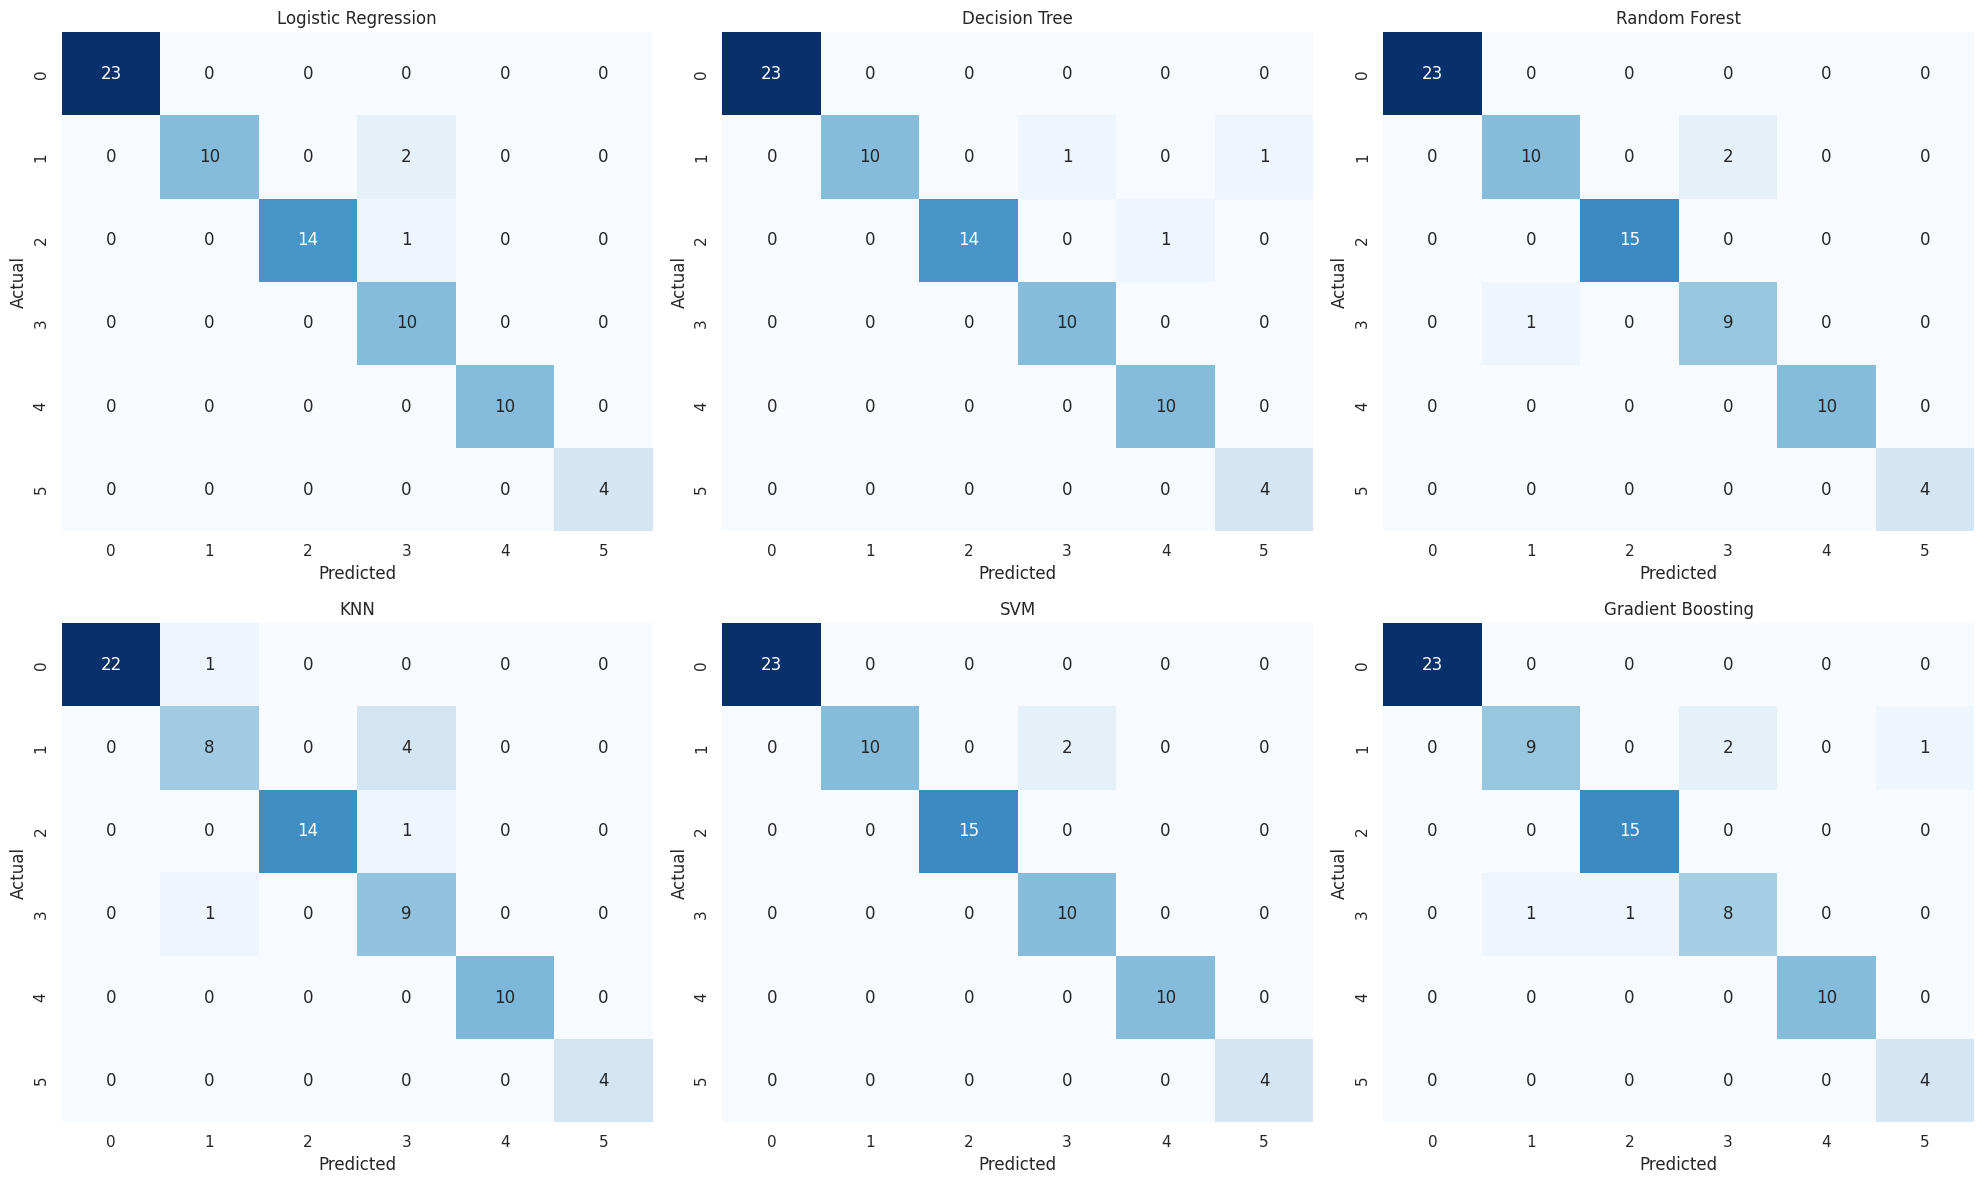

In [38]:
fig, axes = plt.subplots(2, 3, figsize=(20, 12))
axes = axes.ravel()

for i, (name, y_pred) in enumerate(predictions.items()):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[i], cbar=False)
    axes[i].set_title(name)
    axes[i].set_xlabel('Predicted')
    axes[i].set_ylabel('Actual')

plt.tight_layout()
plt.show()

## **10. Hyperparameter Tuning**

Hyperparameter tuning is performed to optimize model performance by identifying the best combination of parameters. `GridSearchCV` with 5-fold cross-validation is used to evaluate different parameter combinations for the strongest candidate models from the initial comparison (Random Forest, SVM, Logistic Regression). The tuned models are then compared with their default versions to determine whether tuning improves predictive performance on this relatively small, imbalanced dataset.


In [39]:
# Random Forest tuning
rf_param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 5, 10, 15],
    'min_samples_split': [2, 5, 10]
}

rf_grid = GridSearchCV(RandomForestClassifier(random_state=42), rf_param_grid,
                        cv=5, scoring='f1_weighted', n_jobs=-1)
rf_grid.fit(X_train_scaled, y_train)

print("Best Random Forest params:", rf_grid.best_params_)
print(f"Best CV F1 score: {rf_grid.best_score_:.4f}")

Best Random Forest params: {'max_depth': 10, 'min_samples_split': 2, 'n_estimators': 100}
Best CV F1 score: 0.9826


In [40]:
# SVM tuning
svm_param_grid = {
    'C': [0.1, 1, 10, 100],
    'kernel': ['linear', 'rbf'],
    'gamma': ['scale', 'auto']
}

svm_grid = GridSearchCV(SVC(probability=True, random_state=42), svm_param_grid,
                         cv=5, scoring='f1_weighted', n_jobs=-1)
svm_grid.fit(X_train_scaled, y_train)

print("Best SVM params:", svm_grid.best_params_)
print(f"Best CV F1 score: {svm_grid.best_score_:.4f}")

Best SVM params: {'C': 0.1, 'gamma': 'scale', 'kernel': 'linear'}
Best CV F1 score: 0.9793


In [41]:
# Logistic Regression tuning
lr_param_grid = {
    'C': [0.01, 0.1, 1, 10, 100],
    'solver': ['lbfgs', 'liblinear']
}

lr_grid = GridSearchCV(LogisticRegression(max_iter=1000, random_state=42), lr_param_grid,
                        cv=5, scoring='f1_weighted', n_jobs=-1)
lr_grid.fit(X_train_scaled, y_train)

print("Best Logistic Regression params:", lr_grid.best_params_)
print(f"Best CV F1 score: {lr_grid.best_score_:.4f}")

Best Logistic Regression params: {'C': 0.01, 'solver': 'liblinear'}
Best CV F1 score: 0.9792


In [42]:
# Evaluate tuned models on the test set
tuned_models = {
    'Random Forest (Tuned)': rf_grid.best_estimator_,
    'SVM (Tuned)': svm_grid.best_estimator_,
    'Logistic Regression (Tuned)': lr_grid.best_estimator_
}

tuned_results = []
tuned_predictions = {}
for name, model in tuned_models.items():
    y_pred = model.predict(X_test_scaled)
    tuned_predictions[name] = y_pred
    tuned_results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, average='weighted', zero_division=0),
        'Recall': recall_score(y_test, y_pred, average='weighted', zero_division=0),
        'F1 Score': f1_score(y_test, y_pred, average='weighted', zero_division=0)
    })

tuned_results_df = pd.DataFrame(tuned_results).sort_values('F1 Score', ascending=False).reset_index(drop=True)
tuned_results_df

,Model,Accuracy,Precision,Recall,F1 Score
0,SVM (Tuned),0.972973,0.977477,0.972973,0.972973
1,Random Forest (Tuned),0.959459,0.960688,0.959459,0.959543
2,Logistic Regression (Tuned),0.945946,0.945946,0.945946,0.945946


## **11. Model Comparison Report**

After training, evaluating and tuning all classification models, their performance is compared using Accuracy, Precision, Recall and weighted F1-Score. This comparison helps identify the model that provides the best predictive performance and generalization ability on unseen patient data. Based on the results, the most suitable model is selected for production/clinical deployment and used for feature importance analysis and new-patient prediction.


In [43]:
final_comparison = pd.concat([results_df, tuned_results_df], ignore_index=True)
final_comparison = final_comparison.sort_values('F1 Score', ascending=False).reset_index(drop=True)
final_comparison

,Model,Accuracy,Precision,Recall,F1 Score
0,SVM,0.972973,0.977477,0.972973,0.972973
1,SVM (Tuned),0.972973,0.977477,0.972973,0.972973
2,Logistic Regression,0.959459,0.968815,0.959459,0.960642
3,Random Forest (Tuned),0.959459,0.960688,0.959459,0.959543
4,Random Forest,0.959459,0.960688,0.959459,0.959543
5,Decision Tree,0.959459,0.964619,0.959459,0.959392
6,Logistic Regression (Tuned),0.945946,0.945946,0.945946,0.945946
7,Gradient Boosting,0.932432,0.933277,0.932432,0.930944
8,KNN,0.905405,0.919305,0.905405,0.908094


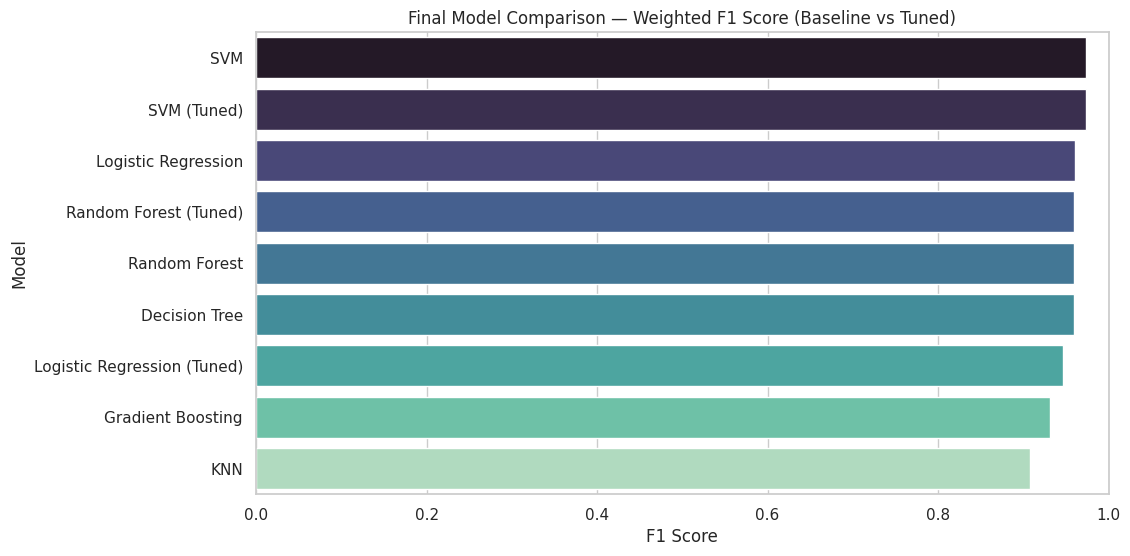

In [44]:
plt.figure(figsize=(11, 6))
sns.barplot(x='F1 Score', y='Model', data=final_comparison, palette='mako')
plt.title('Final Model Comparison — Weighted F1 Score (Baseline vs Tuned)')
plt.xlim(0, 1)
plt.show()

### 11.1 Best Model Selection

Based on the comparison above, the model with the highest weighted F1 score on the held-out test set is selected as the best model for production. The cell below identifies it automatically and stores it in best_model for later use (feature importance, prediction on new patients).

In [45]:
best_row = final_comparison.iloc[0]
best_model_name = best_row['Model']
print(f"Best performing model: {best_model_name}")
print(best_row)

# Map back to the fitted estimator object
all_models_lookup = {**trained_models, **tuned_models}
best_model = all_models_lookup[best_model_name]

Best performing model: SVM
Model             SVM
Accuracy     0.972973
Precision    0.977477
Recall       0.972973
F1 Score     0.972973
Name: 0, dtype: object


## **12. Feature Importance / Interpretation**

Feature importance analysis is performed to identify the clinical and histopathological attributes that have the greatest influence on predicting the skin disease class. This is done using the importance scores from the selected best model (when available). Features with higher importance scores have a greater impact on the model's predictions, while features with lower scores contribute less. This analysis helps clinicians understand which observations are most diagnostic and provides valuable interpretability for a healthcare decision-support use case.


SVM does not expose feature_importances_ or coef_ directly.
Using permutation importance instead.


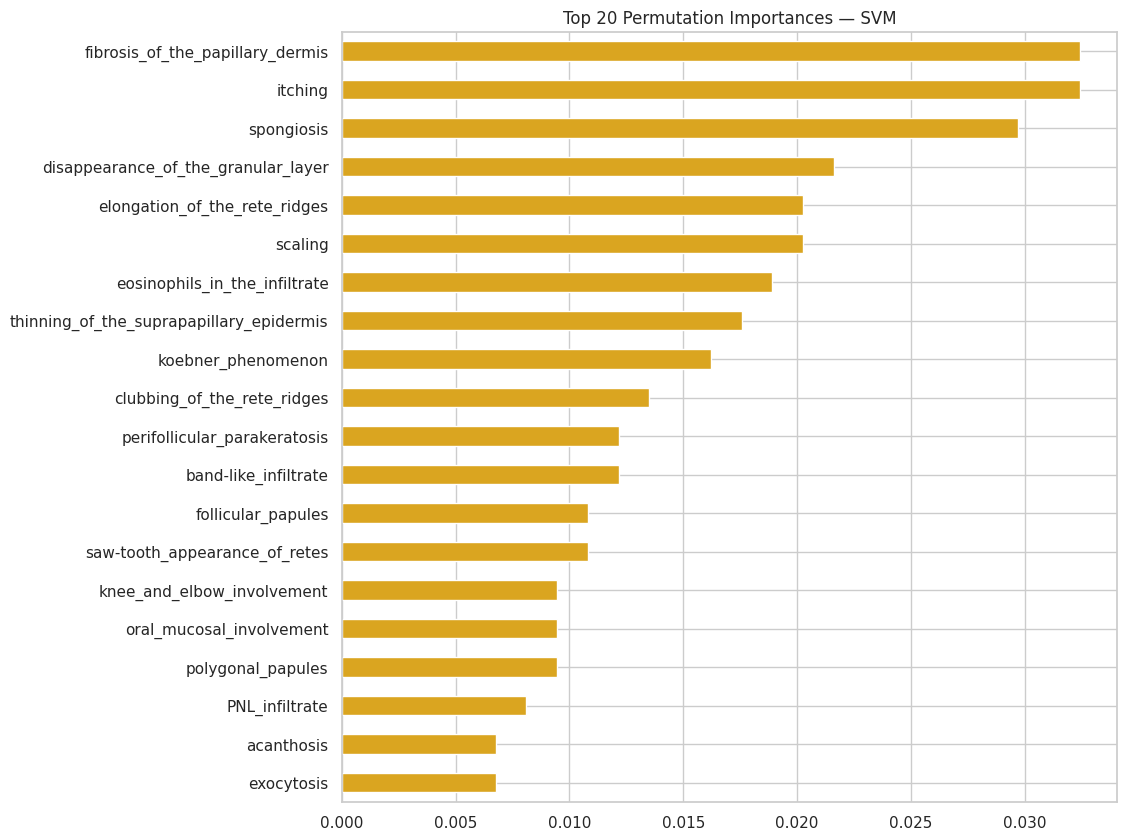

fibrosis_of_the_papillary_dermis            0.032432
itching                                     0.032432
spongiosis                                  0.029730
disappearance_of_the_granular_layer         0.021622
elongation_of_the_rete_ridges               0.020270
scaling                                     0.020270
eosinophils_in_the_infiltrate               0.018919
thinning_of_the_suprapapillary_epidermis    0.017568
koebner_phenomenon                          0.016216
clubbing_of_the_rete_ridges                 0.013514
perifollicular_parakeratosis                0.012162
band-like_infiltrate                        0.012162
follicular_papules                          0.010811
saw-tooth_appearance_of_retes               0.010811
knee_and_elbow_involvement                  0.009459
dtype: float64


In [46]:
if hasattr(best_model, 'feature_importances_'):
    importances = pd.Series(best_model.feature_importances_, index=X.columns).sort_values(ascending=False)

    plt.figure(figsize=(10, 10))
    importances.head(20).plot(kind='barh', color='darkcyan')
    plt.title(f'Top 20 Feature Importances — {best_model_name}')
    plt.gca().invert_yaxis()
    plt.xlabel('Importance')
    plt.show()

    print(importances.head(15))
elif hasattr(best_model, 'coef_'):
    coef_df = pd.DataFrame(best_model.coef_, columns=X.columns)
    mean_abs_coef = coef_df.abs().mean().sort_values(ascending=False)

    plt.figure(figsize=(10, 10))
    mean_abs_coef.head(20).plot(kind='barh', color='indianred')
    plt.title(f'Top 20 Features by Mean |Coefficient| — {best_model_name}')
    plt.gca().invert_yaxis()
    plt.xlabel('Mean absolute coefficient across classes')
    plt.show()

    print(mean_abs_coef.head(15))
else:
    print(f"{best_model_name} does not expose feature_importances_ or coef_ directly.")
    print("Using permutation importance instead.")
    from sklearn.inspection import permutation_importance
    perm = permutation_importance(best_model, X_test_scaled, y_test, n_repeats=10, random_state=42, n_jobs=-1)
    perm_importance = pd.Series(perm.importances_mean, index=X.columns).sort_values(ascending=False)

    plt.figure(figsize=(10, 10))
    perm_importance.head(20).plot(kind='barh', color='goldenrod')
    plt.title(f'Top 20 Permutation Importances — {best_model_name}')
    plt.gca().invert_yaxis()
    plt.show()

    print(perm_importance.head(15))

## **13. Prediction on New Patient**

This section demonstrates the practical application of the trained machine learning model by predicting the disease class of a new patient based on their clinical and histopathological observations. A sample patient record with feature values such as erythema, scaling, itching, family history and various histopathological grades is provided as input. The trained model then predicts the most likely skin disease category, along with the prediction probabilities for all six classes, demonstrating how the model can support dermatologists in making faster, data-driven diagnostic decisions.


In [47]:
# Example: a new patient's clinical + histopathological observations
# (Replace these values with actual patient data as needed)
new_patient = pd.DataFrame([{
    'erythema': 2, 'scaling': 2, 'definite_borders': 2, 'itching': 1,
    'koebner_phenomenon': 0, 'polygonal_papules': 0, 'follicular_papules': 0,
    'oral_mucosal_involvement': 0, 'knee_and_elbow_involvement': 1, 'scalp_involvement': 1,
    'family_history': 0, 'melanin_incontinence': 0, 'eosinophils_in_the_infiltrate': 0,
    'PNL_infiltrate': 1, 'fibrosis_of_the_papillary_dermis': 0, 'exocytosis': 1,
    'acanthosis': 2, 'hyperkeratosis': 1, 'parakeratosis': 2,
    'clubbing_of_the_rete_ridges': 0, 'elongation_of_the_rete_ridges': 2,
    'thinning_of_the_suprapapillary_epidermis': 2, 'spongiform_pustule': 0,
    'munro_microabcess': 0, 'focal_hypergranulosis': 0,
    'disappearance_of_the_granular_layer': 1, 'vacuolisation_and_damage_of_basal_layer': 0,
    'spongiosis': 1, 'saw-tooth_appearance_of_retes': 2, 'follicular_horn_plug': 0,
    'perifollicular_parakeratosis': 0, 'inflammatory_monoluclear_inflitrate': 1,
    'band-like_infiltrate': 0, 'Age': 34
}])

new_patient_scaled = scaler.transform(new_patient)
prediction = best_model.predict(new_patient_scaled)[0]

print(f"Predicted class: {prediction} — {class_names.get(prediction, 'Unknown')}")

if hasattr(best_model, 'predict_proba'):
    proba = best_model.predict_proba(new_patient_scaled)[0]
    proba_df = pd.Series(proba, index=[class_names[c] for c in best_model.classes_]).sort_values(ascending=False)
    print("\nPrediction probabilities:")
    print(proba_df)

Predicted class: 1 — Psoriasis

Prediction probabilities:
Psoriasis                   0.865745
Seboreic dermatitis         0.056853
Chronic dermatitis          0.030201
Pityriasis rosea            0.029327
Lichen planus               0.011599
Pityriasis rubra pilaris    0.006275
dtype: float64


## **14. TASK 3 — Suggestions to Doctors**

Practical, model-informed suggestions for doctors to help identify skin disease at the earliest, per Task 3 of the problem statement:

1. **Prioritise the top diagnostic features identified by the model** (see Section 12) during the clinical exam and histopathology review — these carry the highest discriminative power between the six disease classes and can shorten the diagnostic path.
2. **Use the model as a second-opinion / triage tool, not a replacement for biopsy.** Since several diseases share early-stage features, a low model-confidence prediction (see `predict_proba` output in Section 13) should prompt the doctor to order the confirmatory histopathological work-up sooner rather than later.
3. **Pay close attention to family history and koebner phenomenon early in intake** — these are quick, non-invasive clinical checks that appear among the more informative features and can be recorded at the very first visit.
4. **Age-aware assessment:** since certain classes skew towards particular age groups (Section 6.3), factor patient age into the differential diagnosis, especially for pityriasis rosea (younger patients) versus chronic dermatitis (older patients).
5. **Standardise histopathological grading (0–3 scale)** across labs/pathologists — the model's performance depends directly on consistent, comparable grading of features like acanthosis, parakeratosis and the various rete-ridge features.
6. **Revisit diagnosis at follow-up.** Because some diseases can present with another disease's features at an early stage, a model-supported re-evaluation at the next visit (once more histopathological features stabilise) can catch misclassifications.
7. **Flag rare classes for extra caution.** Class 6 (Pityriasis rubra pilaris) has the fewest training samples, so predictions for this class should be treated with slightly more scepticism and cross-checked manually.


## **15. Challenges Faced**

**1. `Age` Stored as Text with `'?'` Placeholders**<br>
The `Age` column was stored as an object/string dtype instead of numeric because it used `'?'` as a placeholder for missing values instead of `NaN`. This was addressed by replacing `'?'` with `NaN`, converting the column to numeric, and imputing missing values with the median, which is robust to the mild skew in the age distribution.<br><br>

**2. Small, Imbalanced Dataset**<br>
The dataset has only 366 rows spread across 6 classes, ranging from ~20 to ~112 samples per class. A stratified train-test split was used to preserve class proportions, and weighted averaging was used for precision, recall and F1-score so minority classes are not ignored.<br><br>

**3. Many Correlated Ordinal Features**<br>
The dataset contains many highly correlated ordinal (0–3 graded) features, which could bias distance-based models such as KNN and SVM. StandardScaler was applied before training these models to put all features on a comparable scale.<br><br>

**4. Selecting the Best Model Across Different Algorithm Families**<br>
Different machine learning algorithms produced different prediction results. A systematic comparison table (Accuracy, Precision, Recall, F1-Score) combined with GridSearchCV hyperparameter tuning was used to identify the most suitable model.<br><br>

**5. Risk of Overfitting During Tuning**<br>
With a small dataset, tuning on a single validation split risks overfitting to that split. 5-fold cross-validation inside GridSearchCV was used instead, giving a more reliable estimate of generalisation performance.<br><br>

**6. Interpreting Model Predictions for Clinical Use**<br>
Since this is a clinical decision-support context, doctors need to trust and understand the model's reasoning rather than receive a black-box label. Feature importance analysis was used to surface the clinical/histopathological attributes driving each prediction.


## **16. Final Conclusion**

**1.Project Objective:**

The primary objective of this project was to develop a machine learning model capable of predicting the erythemato-squamous disease category (6 classes) of a patient based on clinical and histopathological observations.
<br><br>

**2.Exploratory Data Analysis (EDA):**

A comprehensive Exploratory Data Analysis was conducted to understand the dataset by examining its structure, checking for missing/placeholder values and duplicates, analysing class distribution and imbalance, studying the Age distribution across classes, identifying outliers, and exploring correlations between features and the target variable.
<br><br>

**3.Model Development and Evaluation:**

Six machine learning classification models — Logistic Regression, Decision Tree, Random Forest, K-Nearest Neighbors (KNN), Support Vector Machine (SVM), and Gradient Boosting — were trained, evaluated, and compared using Accuracy, Precision, Recall, F1-Score, Classification Report and Confusion Matrix to identify the best-performing model.
<br><br>

**4.Model Optimization:**

The strongest candidate models were further optimized through Hyperparameter Tuning (GridSearchCV with 5-fold cross-validation), and the best resulting model is recommended for use as a clinical decision-support tool due to its high predictive performance and reliability.
<br><br>

**5.Feature Importance Analysis:**

Feature Importance analysis identified the clinical and histopathological attributes that most influence disease classification, aligning with known dermatological diagnostic criteria and providing valuable interpretability for clinical use.
<br><br>

**6.Practical Application:**

The selected model was tested on a new patient's clinical and histopathological observations and successfully predicted the most likely disease category along with class probabilities, demonstrating its usefulness as a real-world diagnostic support tool.
<br><br>

**7.Business / Clinical Impact and Conclusion:**

Overall, this project proves that machine learning can effectively support dermatological diagnosis, helping doctors identify the correct skin disease category earlier, reduce dependence on invasive biopsies, and make more confident, data-driven clinical decisions. Practical suggestions for doctors were also compiled (Section 14) as required by Task 3.
<br><br>

**8.Future Enhancements:**

Future enhancements can include collecting a larger and more balanced patient dataset, applying advanced ensemble/boosting techniques, incorporating additional real-world clinical indicators, and deploying the optimized model as a web application or API for real-time, in-clinic decision support.


# **17. Project Links**

The following links provide access to the complete project resources, including the source code, dataset, and supporting documentation.

## **1. GitHub Repository**
Access the complete source code, Jupyter Notebook, README, and project files.

🔗 **GitHub Repository:**
https://github.com/Sameekshagithub/PRCP-1027-Skin-Disorder-Prediction-Using-Machine-Learning

---

## **2. Google Drive**
Access the PPT and REPORT.

🔗 **Google Drive:**
https://drive.google.com/drive/folders/1he39tYwiGjgyDrXQnFwKcg5_Hzwfkw2P?usp=drive_link

---

**Project Code:** PRCP-1027
**Team Code:** PTID-AIE-JUL-26-11142
